In [5]:
pip install pandas

In [6]:
# Import required Libraries

import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

In [9]:
# Load the CSV file

df = pd.read_csv('../SyntheticData_Training.csv')
df.head()

,studyid_adm,agecalc_adm,height_cm_adm,weight_kg_adm,muac_mm_adm,hr_bpm_adm,rr_brpm_app_adm,sysbp_mmhg_adm,diasbp_mmhg_adm,temp_c_adm,...,cookloc_adm,lightfuel_adm,tobacco_adm,bednet_adm,hctpretransfusion_adm,hivstatus_adm,malariastatuspos_adm,lengthadm,caregiver_adm_new,inhospital_mortality
0,1,16.8,79.8,11.6,150.0,130.0,23.0,92.0,54.0,36.3,...,In a separate building/building space used as ...,Electric bulbs (national grid),Never,Always,Yes,HIV negative,No,2,Mother,0
1,2,46.1,93.0,13.6,151.0,115.0,35.0,72.0,42.0,36.8,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,Yes,5,Mother,0
2,3,7.9,68.2,8.2,148.0,150.0,56.0,94.0,51.0,37.2,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,No,4,Mother,0
3,4,38.2,95.0,12.0,138.0,134.0,38.0,94.0,57.0,37.6,...,In the house where you sleep,Electric bulbs (national grid),Never,Always,NaN,HIV negative,Yes,5,Mother,0
4,5,16.1,83.0,12.0,165.0,163.0,61.0,107.0,73.0,38.7,...,Outdoors in the open,Electric bulbs (national grid),Never,Sometimes,Yes,HIV negative,Yes,7,Mother,0


In [12]:
# retrieving columns Label
df.columns


Index(['studyid_adm', 'agecalc_adm', 'height_cm_adm', 'weight_kg_adm',
       'muac_mm_adm', 'hr_bpm_adm', 'rr_brpm_app_adm', 'sysbp_mmhg_adm',
       'diasbp_mmhg_adm', 'temp_c_adm',
       ...
       'cookloc_adm', 'lightfuel_adm', 'tobacco_adm', 'bednet_adm',
       'hctpretransfusion_adm', 'hivstatus_adm', 'malariastatuspos_adm',
       'lengthadm', 'caregiver_adm_new', 'inhospital_mortality'],
      dtype='object', length=140)

In [11]:
# Dataframe shape
df.shape

(2686, 140)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2686 entries, 0 to 2685
Columns: 140 entries, studyid_adm to inhospital_mortality
dtypes: float64(23), int64(3), object(114)
memory usage: 2.9+ MB


In [ ]:
# Check for null values
df.isnull().sum()

studyid_adm              0
agecalc_adm              0
height_cm_adm           14
weight_kg_adm            9
muac_mm_adm             13
                        ..
hivstatus_adm            5
malariastatuspos_adm     2
lengthadm                0
caregiver_adm_new        3
inhospital_mortality     0
Length: 140, dtype: int64

In [ ]:
# Filter and print columns with non-zero null value counts
columns_with_null = null_counts[null_counts > 0].index
print(df[columns_with_null])

      height_cm_adm  weight_kg_adm  muac_mm_adm  hr_bpm_adm  rr_brpm_app_adm  \
0              79.8           11.6        150.0       130.0             23.0   
1              93.0           13.6        151.0       115.0             35.0   
2              68.2            8.2        148.0       150.0             56.0   
3              95.0           12.0        138.0       134.0             38.0   
4              83.0           12.0        165.0       163.0             61.0   
...             ...            ...          ...         ...              ...   
2681           98.2           10.0        135.0       163.0             61.0   
2682           82.3           10.0        140.0       115.0             37.0   
2683           82.4           12.7        145.0       150.0             40.0   
2684           67.5            7.5        130.0       145.0             26.0   
2685           77.8            8.0        131.0       146.0             38.0   

      sysbp_mmhg_adm  diasbp_mmhg_adm  

In [ ]:
df.describe()


,studyid_adm,agecalc_adm,height_cm_adm,weight_kg_adm,muac_mm_adm,hr_bpm_adm,rr_brpm_app_adm,sysbp_mmhg_adm,diasbp_mmhg_adm,temp_c_adm,...,alivechildren_adm,deadchildren_adm,hematocrit_gpdl_adm,lactate_mmolpl_adm,lactate2_mmolpl_adm,glucose_mmolpl_adm,sqi1_perc_oxi_adm,sqi2_perc_oxi_adm,lengthadm,inhospital_mortality
count,2686.000000,2686.00000,2672.000000,2677.000000,2673.000000,2685.000000,2681.000000,2684.000000,2685.000000,2685.000000,...,2682.00000,2685.000000,2229.000000,2222.000000,469.000000,2677.000000,2556.000000,2479.000000,2686.000000,2686.000000
mean,1343.500000,21.12338,79.659401,9.577265,138.076693,141.219367,46.179784,96.941133,54.594041,37.470503,...,3.02349,0.354935,32.954240,2.774887,2.951599,6.320882,88.780516,78.004841,5.377141,0.044304
std,775.525736,13.05725,11.110075,2.796121,15.934621,25.550612,14.871732,11.876974,11.005274,1.007606,...,1.81805,0.810868,9.750002,2.123403,2.234946,2.512912,16.714758,23.383975,7.654527,0.205808
min,1.000000,5.90000,56.000000,2.610000,75.000000,42.000000,17.000000,58.000000,15.000000,33.600000,...,0.00000,0.000000,6.000000,0.500000,0.200000,0.000000,0.000000,0.000000,-85.000000,0.000000
25%,672.250000,10.52500,71.500000,7.640000,130.000000,128.000000,35.000000,89.000000,48.000000,36.700000,...,2.00000,0.000000,28.000000,1.500000,1.400000,5.000000,87.000000,68.000000,3.000000,0.000000
50%,1343.500000,16.90000,78.000000,9.000000,140.000000,143.000000,44.000000,96.000000,54.000000,37.200000,...,3.00000,0.000000,34.000000,2.100000,2.300000,6.000000,96.000000,87.000000,4.000000,0.000000
75%,2014.750000,28.67500,86.700000,11.000000,149.000000,158.000000,56.000000,104.000000,62.000000,38.200000,...,4.00000,0.000000,40.000000,3.300000,3.700000,7.200000,99.000000,96.000000,6.000000,0.000000
max,2686.000000,61.80000,122.000000,22.000000,190.000000,214.000000,116.000000,159.000000,103.000000,40.600000,...,11.00000,9.000000,82.000000,18.900000,15.900000,24.200000,99.000000,99.000000,210.000000,1.000000


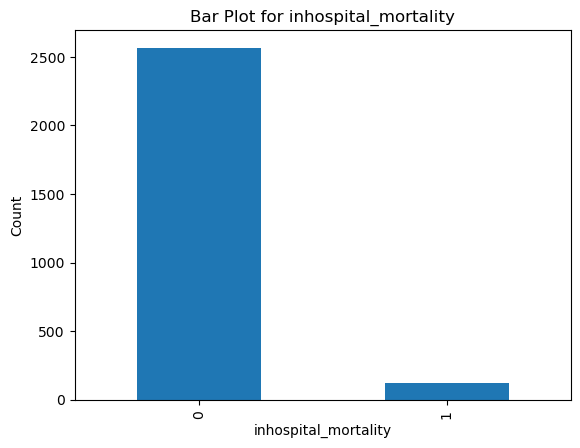

In [ ]:
# Inhospital_mortality label balance
# Specify the column name
column_name = 'inhospital_mortality'  # Replace with the actual column name

# Create a bar plot of the specified column
df[column_name].value_counts().plot(kind='bar')

# Set plot title and labels
plt.title('Bar Plot for {}'.format(column_name))
plt.xlabel(column_name)
plt.ylabel('Count')

# Display the plot
plt.show()

In [ ]:
column_name = 'inhospital_mortality'  #
total_count = len(df)  # Total count of rows in the DataFrame
mortality_count = df[column_name].value_counts().get(1, 0)  # Count of '1' values in the column

percentage = (mortality_count / total_count) * 100

print("Percentage of mortality values in {}: {:.2f}%".format(column_name, percentage))

Percentage of mortality values in inhospital_mortality: 4.43%


In [ ]:
def plots(column_name):
  
    # Create a figure with subplots
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    # Plot histogram for a column
    axes[0].hist(df[column_name])
    axes[0].set_title('Histogram of {}'.format(column_name))
    axes[0].set_xlabel(column_name)
    axes[0].set_ylabel('Frequency')

    # Create a boxplot based on attrition
    sns.boxplot(data=df, x='inhospital_mortality', y=column_name, ax=axes[1])
    axes[1].set_title('Boxplot of {} by inhospital_mortality'.format(column_name))
    axes[1].set_xlabel('inhospital_mortality')
    axes[1].set_ylabel(column_name)

    # Create a violin plot to visualize selected column distribution by attrition
    sns.violinplot(data=df, x='inhospital_mortality', y=column_name, ax=axes[2])
    axes[2].set_title('Distribution of {} by inhospital_mortality'.format(column_name))
    axes[2].set_xlabel('inhospital_mortality')
    axes[2].set_ylabel(column_name)

    # Adjust the spacing between subplots
    plt.tight_layout()

    # Show the plots
    plt.show()

In [ ]:
# statistical significance functions
# testing normality
# H0:normal
# H1: not normal
def normality (column_name):
    stat, p = stats.shapiro(df[column_name])
    if p < 0.05:
        return " for '{}'distirbution is not normal".format(column_name)
    else:
        return "for '{}'distirbution is normal".format(column_name)
    
#testing mean equality a t-test for equal variance, the hypotheses are:
# H<sub>0</sub>: averages are equal
# H<sub>a</sub>: averages are not equal
def mean_equal (column_name):
    mortality_average = df[df['inhospital_mortality']==1][column_name]
    alive_average = df[df['inhospital_mortality']==0][column_name]
    stat, p = stats.ttest_ind( mortality_average, alive_average)
    if p < 0.05:
        return "average are not equal"
    else:
        return "average are equal"
    
 # average equality for non equal variance   
def equalmean_inequalvariance(column_name):
    alive= df[df['inhospital_mortality']==0][column_name]
    mortality = df[df['inhospital_mortality']==1][column_name]
    stat, p = stats.ttest_ind(alive, mortality, equal_var=False)
    if p < 0.05:
        return "average are not equal"
    else:
        return "average are equal"
 # average equality for equal variance
def mean_equal_all (column_name):
    alive= df[df['inhospital_mortality']==0][column_name]
    mortality = df[df['inhospital_mortality']==1][column_name]
    stat, p = stats.levene(alive,mortality)
    if p < 0.05:
        return "variance is not equal".format(column_name), equalmean_inequalvariance(column_name)
    else:
        return "variance is equal".format(column_name), mean_equal(column_name)


In [ ]:
def plots_statistical_analysis(column_name):
    plots(column_name)
    return normality(column_name),mean_equal_all(column_name)

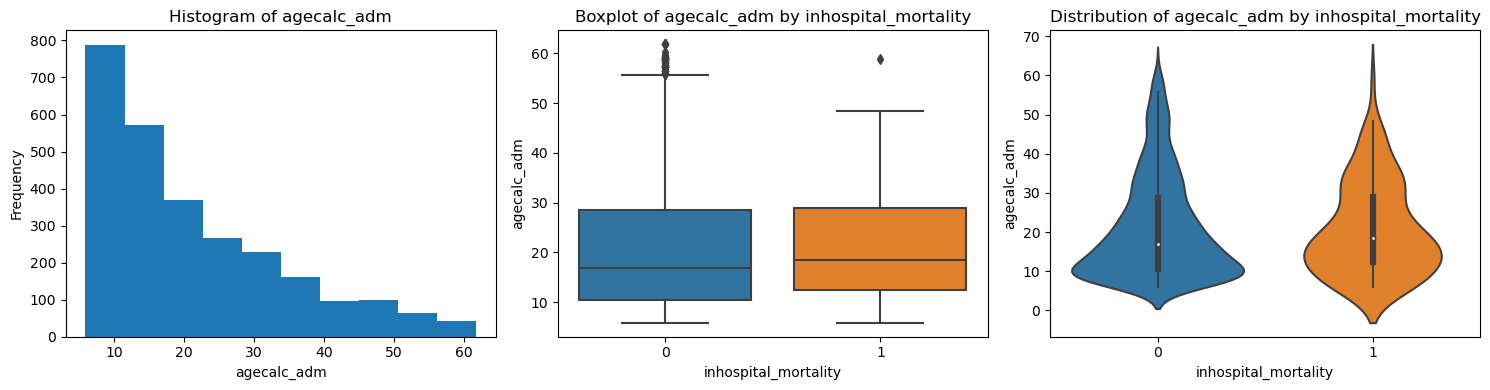

(" for 'agecalc_adm'distirbution is not normal",
 ('variance is equal', 'average are equal'))

In [ ]:
plots_statistical_analysis('agecalc_adm')


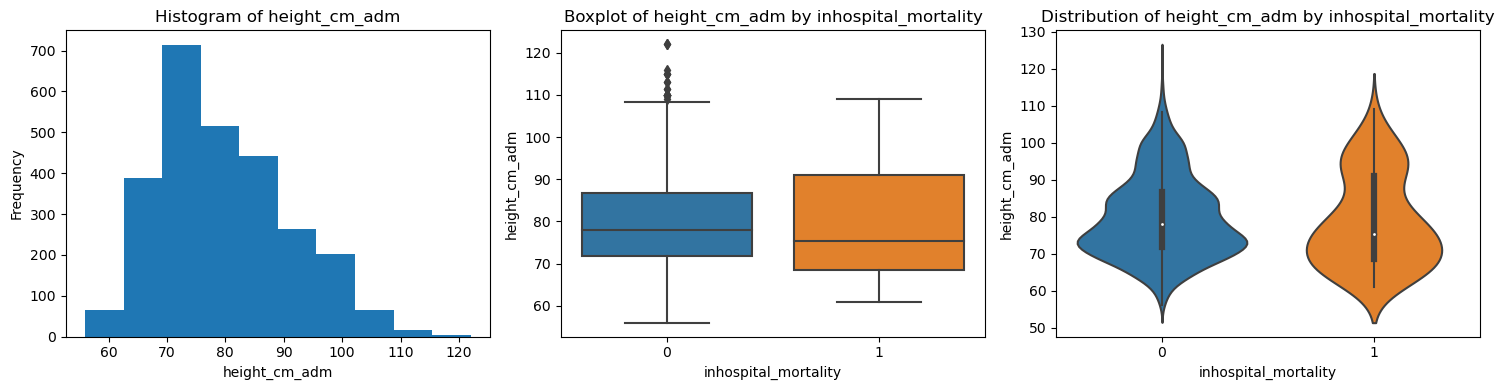

("for 'height_cm_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [ ]:
plots_statistical_analysis('height_cm_adm')

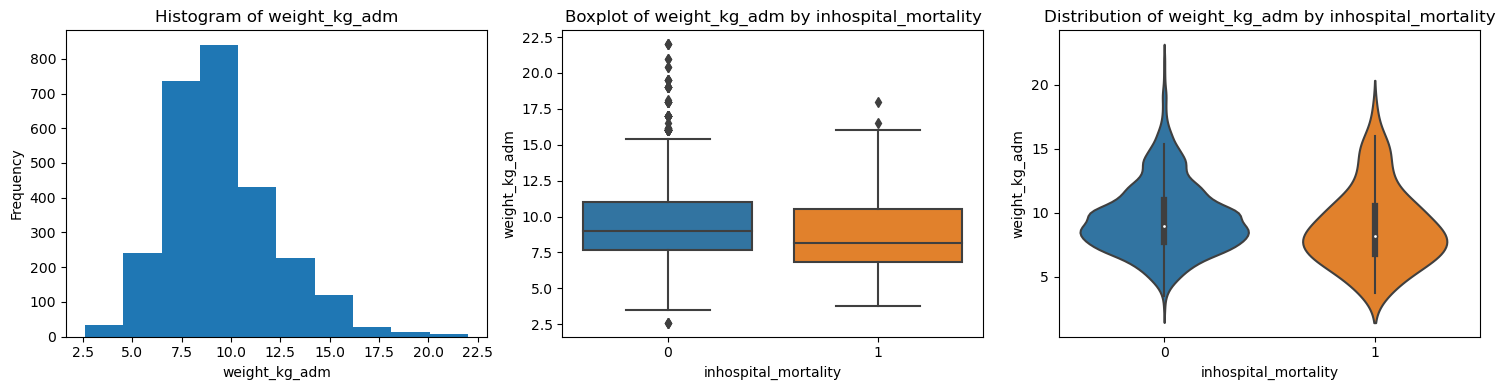

("for 'weight_kg_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [ ]:
plots_statistical_analysis('weight_kg_adm')